# 03 · Baseline (E1) and conventional augmentation (E2) across architectures

Every architecture is trained with its own Optuna-selected hyper-parameters (notebook 02) on the identical E1 training set: 1,000 real A images, 500 per class, one image per patient. Each is trained with 3 seeds.

**Evaluation protocol**
* model selection (checkpoint) and decision threshold (Youden's J) come from **A-validation only**
* the same checkpoint and threshold are applied unchanged to internal **Test A** (624 images, official Kermany test set) and to external **B** (RSNA / NIH, adults)
* B primary task: *Lung Opacity* (n = 7,106) vs *Normal* (n = 9,790); secondary: *Lung Opacity* vs all other studies
* uncertainty: mean ± SD over seeds; patient-clustered bootstrap for paired comparisons

### Metrics primer
| Metric | Meaning | Depends on threshold? | Depends on prevalence? |
|---|---|---|---|
| **AUROC** | probability that a random positive gets a higher score than a random negative; 0.5 = chance, 1 = perfect ranking | no | no |
| **Sensitivity** (recall, TPR) | share of pneumonia/opacity cases flagged | yes | no |
| **Specificity** (TNR) | share of negatives correctly left unflagged | yes | no |
| **F1** | harmonic mean of precision and sensitivity | yes | **yes**: not comparable between A (63% positive) and B (42%) |
| **Val BCE** | log-loss on A-validation; used for checkpoint and HPO selection | no | weakly |

**AUROC is the primary metric** because it does not depend on the threshold or on prevalence, both of which differ between hospitals. Sensitivity and specificity *at the frozen A threshold* show what would happen if the model were deployed unchanged at hospital B. That is usually the more sobering view.

### The architectures
| | type | params | notes |
|---|---|---|---|
| ResNet-18 / 50 | CNN (2015) | 11M / 24M | the classic baseline family; ResNet-18 is the backbone named in the project plan |
| DenseNet-121 | CNN (2017) | 7M | dense connections; the CheXNet backbone, de-facto standard in CXR papers |
| EfficientNet-B0 | CNN (2019) | 4M | compound-scaled, very parameter-efficient |
| ConvNeXt-Tiny | CNN (2022) | 28M | "modernised ResNet" with transformer-style design choices; ImageNet-22k pretraining |
| ViT-S/16 | transformer (2020) | 22M | images as 16×16 patch tokens with global self-attention; weak inductive bias, needs strong pretraining (IN-21k here) |
| Swin-T | transformer (2021) | 28M | windowed attention with a hierarchical, CNN-like pyramid; IN-22k pretraining |

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "reports/results"; RES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)

from cxr.analysis import collect_runs, mean_sd, compare, select_archs, strata_runs, EVAL_LABELS, STRATA_LABELS
from cxr.models import ARCHS
runs = collect_runs()
runs.to_csv(RES / "runs.csv", index=False)
arch_order = [a for a in ARCHS if a in set(runs.arch)]
e12 = runs[runs.experiment.isin(["E1", "E2"])]
print(len(runs), "rows;", e12.groupby("experiment").arch.nunique().to_dict(), "architectures with E1/E2 runs")

/home/edelweizse/Projects/uni/AIE/final/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


252 rows; {'E1': 7, 'E2': 7} architectures with E1/E2 runs


## E1: real-data baseline
Read the table column-wise. **Val** columns are in-domain and saturated (shortcut). **Test A** is internal but assembled differently from training. **B** is the external hospital. A strong model on A that drops sharply on B is the failure mode this project studies.

In [2]:
METRICS = ["auroc", "sensitivity", "specificity", "f1"]
def wide(exp):
    d = runs[runs.experiment == exp]
    parts = []
    for key, lab in EVAL_LABELS.items():
        t = mean_sd(d[d["eval"] == key], "arch", METRICS)
        parts.append(t.drop(columns="seeds").add_prefix(f"{lab} | "))
    val = mean_sd(d.drop_duplicates(["arch", "seed"]), "arch", ["best_val_loss", "best_val_auroc"], "{:.4f}")
    return pd.concat([val] + parts, axis=1).reindex(arch_order)

e1_table = wide("E1")
e1_table.to_csv(RES / "e1_architectures.csv")
display(e1_table[[c for c in e1_table if "AUROC" in c.upper() or "val" in c or c == "seeds"]])
display(e1_table[[c for c in e1_table if "sensitivity" in c or "specificity" in c]])

,best_val_loss,best_val_auroc,seeds,Test A (internal) | auroc,B: opacity vs normal | auroc,B: opacity vs all | auroc
arch,,,,,,
resnet18,0.0631 ± 0.0052,0.9977 ± 0.0013,3,0.945 ± 0.005,0.876 ± 0.032,0.750 ± 0.027
resnet50,0.0545 ± 0.0075,0.9981 ± 0.0005,3,0.947 ± 0.004,0.865 ± 0.022,0.745 ± 0.016
densenet121,0.0442 ± 0.0058,0.9989 ± 0.0003,3,0.932 ± 0.020,0.883 ± 0.017,0.755 ± 0.016
efficientnet_b0,0.0439 ± 0.0143,0.9991 ± 0.0005,3,0.937 ± 0.005,0.859 ± 0.004,0.736 ± 0.002
convnext_tiny,0.0595 ± 0.0037,0.9967 ± 0.0017,3,0.867 ± 0.098,0.839 ± 0.037,0.723 ± 0.033
vit_small,0.0792 ± 0.0116,0.9949 ± 0.0011,3,0.866 ± 0.075,0.823 ± 0.016,0.711 ± 0.016
swin_tiny,0.0810 ± 0.0133,0.9946 ± 0.0042,3,0.878 ± 0.040,0.838 ± 0.012,0.712 ± 0.016


,Test A (internal) | sensitivity,Test A (internal) | specificity,B: opacity vs normal | sensitivity,B: opacity vs normal | specificity,B: opacity vs all | sensitivity,B: opacity vs all | specificity
arch,,,,,,
resnet18,0.994 ± 0.001,0.674 ± 0.036,0.886 ± 0.051,0.715 ± 0.103,0.886 ± 0.051,0.483 ± 0.101
resnet50,0.988 ± 0.004,0.754 ± 0.024,0.839 ± 0.059,0.737 ± 0.116,0.839 ± 0.059,0.526 ± 0.115
densenet121,0.995 ± 0.003,0.670 ± 0.062,0.906 ± 0.022,0.705 ± 0.050,0.906 ± 0.022,0.461 ± 0.047
efficientnet_b0,0.998 ± 0.001,0.571 ± 0.065,0.895 ± 0.068,0.612 ± 0.163,0.895 ± 0.068,0.409 ± 0.146
convnext_tiny,0.995 ± 0.003,0.595 ± 0.120,0.868 ± 0.039,0.688 ± 0.081,0.868 ± 0.039,0.481 ± 0.076
vit_small,0.989 ± 0.004,0.637 ± 0.070,0.877 ± 0.032,0.564 ± 0.084,0.877 ± 0.032,0.384 ± 0.077
swin_tiny,0.996 ± 0.001,0.645 ± 0.074,0.902 ± 0.014,0.666 ± 0.070,0.902 ± 0.014,0.434 ± 0.050


### Insights: E1 baseline
* **Classic CNNs are the strongest and most stable baselines at 1,000 images.** ResNet-18/50, DenseNet-121 and EfficientNet-B0 reach Test A AUROC 0.93–0.95 (SD ≤ 0.02) and B 0.86–0.88. ConvNeXt-T, ViT-S and Swin-T are clearly worse on B (0.82–0.84) and unstable on Test A (SD 0.04–0.10; single seeds as low as 0.77–0.80). Bigger, more modern models with weaker inductive biases need more data or stronger regularisation than 1,000 images and no augmentation provide.
* **Every model loses ground on the external hospital:** Test A → B drops by 0.03–0.08 AUROC. Note that the drop alone is not a quality measure: the transformers have the *smallest* drops only because their Test A scores are already low.
* **At the frozen threshold the models over-call pneumonia on B.** Sensitivity stays high (0.84–0.91) while specificity is low (0.56–0.74). It was already the weak side on Test A (0.57–0.75), because the A-validation threshold sits low. When B's "not normal" studies are counted as negatives, specificity collapses to 0.38–0.53: the model calls most abnormal-but-not-pneumonia images pneumonia, because A never showed it other diseases.
* **Val AUROC ≈0.995–0.999 for every architecture** says nothing about which one transfers (the notebook-01 shortcut).

### Confounding by acquisition view in B
In B, AP radiographs (portable, often sicker inpatients) carry opacity in about 40% of studies, versus 10% for PA. A model that simply scores AP films higher gets credit in the pooled AUROC without detecting opacity. Within-view AUROC removes this shortcut and is reported as a robustness endpoint.

In [3]:
strata = strata_runs(runs[runs.experiment.isin(["E1", "E2"])])
st_tab = pd.concat([mean_sd(strata[(strata.experiment == e) & (strata["eval"] == k)], "arch", ["auroc"]).drop(columns="seeds")
                    .rename(columns={"auroc": f"{e} | {lab}"}) for e in ["E1", "E2"] for k, lab in STRATA_LABELS.items()], axis=1)
display(st_tab.reindex(arch_order))
st_tab.to_csv(RES / "e1_e2_view_stratified.csv")

,E1 | B PA only: opacity vs normal,E1 | B AP only: opacity vs normal,E2 | B PA only: opacity vs normal,E2 | B AP only: opacity vs normal
arch,,,,
resnet18,0.798 ± 0.021,0.741 ± 0.072,0.841 ± 0.005,0.795 ± 0.034
resnet50,0.775 ± 0.022,0.718 ± 0.033,0.817 ± 0.033,0.829 ± 0.039
densenet121,0.811 ± 0.014,0.764 ± 0.028,0.854 ± 0.010,0.819 ± 0.046
efficientnet_b0,0.767 ± 0.019,0.707 ± 0.029,0.843 ± 0.011,0.830 ± 0.060
convnext_tiny,0.757 ± 0.032,0.672 ± 0.051,0.809 ± 0.015,0.807 ± 0.014
vit_small,0.707 ± 0.007,0.675 ± 0.041,0.757 ± 0.092,0.786 ± 0.081
swin_tiny,0.765 ± 0.017,0.636 ± 0.039,0.816 ± 0.056,0.675 ± 0.115


**Insight: a sizeable part of pooled B AUROC is view recognition.** Within PA films alone, E1 AUROC is 0.71–0.81. Within AP films it is 0.64–0.76. Pooled, it is 0.82–0.88. Because AP films carry 4× more opacity *and* look different, a model gets "free" AUROC for scoring AP films higher. A fairer statement of E1's external performance is therefore "≈0.75–0.80 within comparable acquisitions". This should be kept in mind whenever pooled B numbers are quoted.

,A_test,B,drop,drop_sd
arch,,,,
resnet18,0.945,0.876,0.069,0.032
resnet50,0.947,0.865,0.081,0.020
densenet121,0.932,0.883,0.049,0.003
efficientnet_b0,0.937,0.859,0.078,0.002
convnext_tiny,0.867,0.839,0.028,0.072
vit_small,0.866,0.823,0.043,0.059
swin_tiny,0.878,0.838,0.040,0.029


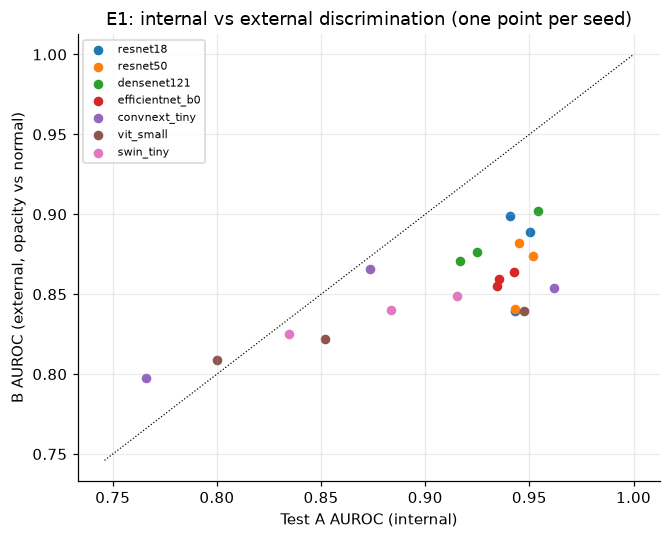

In [4]:
# generalisation gap per architecture (paired by seed)
piv = runs[runs.experiment == "E1"].pivot_table(index=["arch", "seed"], columns="eval", values="auroc")
piv["drop_A_to_B"] = piv["A_test:label"] - piv["B_external:label"]
gap = piv.groupby("arch").agg(A_test=("A_test:label", "mean"), B=("B_external:label", "mean"),
                              drop=("drop_A_to_B", "mean"), drop_sd=("drop_A_to_B", "std")).reindex(arch_order)
display(gap.round(3))

fig, ax = plt.subplots(figsize=(6.2, 5))
for arch in arch_order:
    d = piv.loc[arch]
    ax.scatter(d["A_test:label"], d["B_external:label"], s=28, label=arch)
lims = [min(piv["B_external:label"].min(), piv["A_test:label"].min()) - 0.02, 1.0]
ax.plot(lims, lims, "k:", lw=0.8); ax.set_xlabel("Test A AUROC (internal)"); ax.set_ylabel("B AUROC (external, opacity vs normal)")
ax.set_title("E1: internal vs external discrimination (one point per seed)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "e1_internal_vs_external.png", bbox_inches="tight"); plt.show()

**How to read the scatter.** Each point is one trained model (architecture × seed). Points on the dotted diagonal would generalise perfectly from A to B; the vertical distance below it is the generalisation gap. A cloud spread *horizontally* means unstable internal performance across seeds; spread *vertically* means the external result depends on luck of initialisation and batch order. Both are reasons to report several seeds.

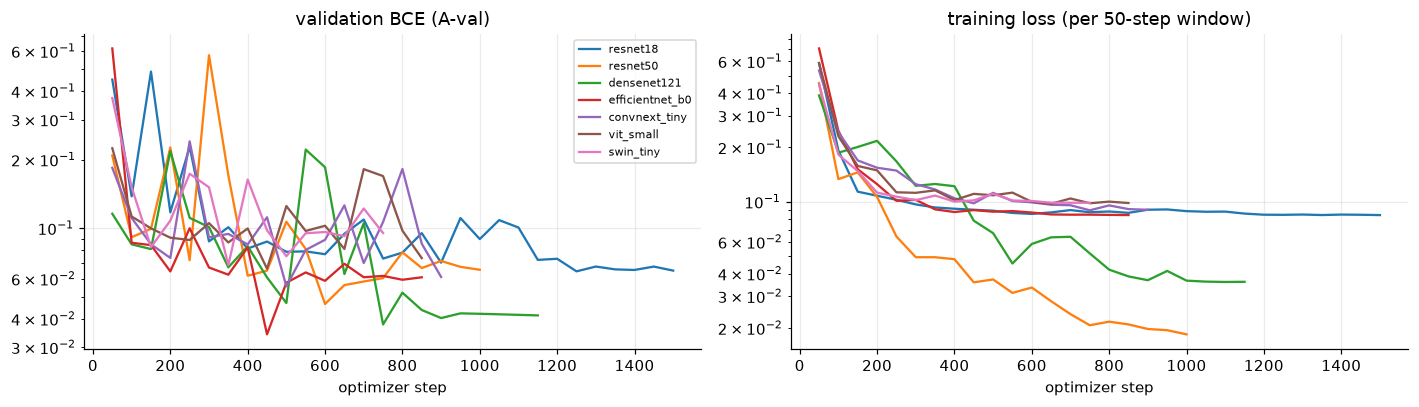

In [5]:
# learning curves (seed 0)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for arch in arch_order:
    p = ROOT / f"artifacts/runs/E1/{arch}/seed0/history.csv"
    if p.exists():
        h = pd.read_csv(p)
        axes[0].plot(h.step, h.val_loss, label=arch); axes[1].plot(h.step, h.train_loss, label=arch)
axes[0].set_title("validation BCE (A-val)"); axes[1].set_title("training loss (per 50-step window)")
for ax in axes: ax.set_xlabel("optimizer step"); ax.set_yscale("log")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(FIG / "e1_learning_curves.png", bbox_inches="tight"); plt.show()

In [6]:
sel = select_archs(runs, k=2)
order = runs[runs.experiment == "E1"].drop_duplicates(["arch", "seed"]).groupby("arch").best_val_loss.mean().sort_values()
display(Markdown(f"**Selection rule (fixed in advance):** rank by mean E1 A-validation BCE → best CNN and best transformer "
                 f"go into the data experiments. Ranking: {', '.join(f'{a} ({v:.4f})' for a, v in order.items())}. "
                 f"**Selected: {', '.join(sel)}**. B played no role in this choice."))

**Selection rule (fixed in advance):** rank by mean E1 A-validation BCE → best CNN and best transformer go into the data experiments. Ranking: efficientnet_b0 (0.0439), densenet121 (0.0442), resnet50 (0.0545), convnext_tiny (0.0595), resnet18 (0.0631), vit_small (0.0792), swin_tiny (0.0810). **Selected: efficientnet_b0, vit_small**. B played no role in this choice.

**Learning curves.** Validation BCE typically falls within the first few hundred steps and then rises slowly while training loss keeps falling: classic over-fitting on 1,000 images. Early stopping keeps the checkpoint at the validation minimum (marked runs stop 400 steps after it). Curves that are jagged from step to step show the noise level of a 682-image validation set: one or two confidently wrong images move BCE visibly.

## E2: conventional augmentation vs E1
E2 applies random, mild, anatomically plausible perturbations to every training batch on the GPU:
* rotation ±10°, translation ±6%, scale ±10% (affine, border-replicated)
* brightness ±15%, contrast ±15%, gamma ±15%
* each image is perturbed with probability 0.9

There are deliberately **no horizontal flips** (they move the heart to the wrong side and mirror text markers) and **no elastic warps** (unrealistic anatomy).

Why might this help *external* generalisation? Brightness, contrast and gamma jitter simulates different detectors and post-processing. Small geometric jitter simulates different positioning and collimation. Both make the exact pixel statistics that encode A's acquisition shortcut less reliable, pushing the model towards features that survive those perturbations.

In [7]:
e2_table = wide("E2")
e2_table.to_csv(RES / "e2_architectures.csv")
rows = []
for arch in arch_order:
    for key in list(EVAL_LABELS) + list(STRATA_LABELS):
        r = compare("E1", "E2", arch, key)
        if r: rows.append(r)
e2_vs_e1 = pd.DataFrame(rows)
e2_vs_e1.to_csv(RES / "e2_vs_e1.csv", index=False)
ALL_LABELS = {**EVAL_LABELS, **STRATA_LABELS}
show = e2_vs_e1.assign(eval=e2_vs_e1["eval"].map(ALL_LABELS)).pivot(index="arch", columns="eval",
        values=["delta_per_seed_mean", "delta_ensemble", "ci_lo", "ci_hi", "p_boot"]).reindex(arch_order)
display(show.round(3))

delta_per_seed_mean                                                                                                     delta_ensemble  \
eval            B AP only: opacity vs normal B PA only: opacity vs normal B: opacity vs all B: opacity vs normal Test A (internal) B AP only: opacity vs normal   
arch                                                                                                                                                              
resnet18                               0.054                        0.043             0.018                0.030            -0.005                        0.051   
resnet50                               0.111                        0.042             0.032                0.042             0.021                        0.105   
densenet121                            0.055                        0.044             0.023                0.032             0.015                        0.064   
efficientnet_b0                        0.123                        0.076             0.042                0.056            -0.006                        0.130   
convnext_tiny                          0.135                        0.052             0.054                0.061             0.087                        0.127   
vit_small                              0.111                        0.050             0.034                0.044             0.059                        0.111   
swin_tiny                              0.039                        0.052             0.024                0.032             0.006                        0.058   

                                                                                                                             ci_lo                                                 \
eval            B PA only: opacity vs normal B: opacity vs all B: opacity vs normal Test A (internal) B AP only: opacity vs normal B PA only: opacity vs normal B: opacity vs all   
arch                                                                                                                                                                                
resnet18                               0.037             0.014                0.022            -0.005                        0.043                        0.032             0.012   
resnet50                               0.030             0.026                0.031             0.012                        0.096                        0.024             0.024   
densenet121                            0.038             0.019                0.023             0.008                        0.055                        0.033             0.016   
efficientnet_b0                        0.074             0.043                0.052            -0.008                        0.119                        0.066             0.040   
convnext_tiny                          0.042             0.042                0.043             0.043                        0.117                        0.036             0.040   
vit_small                              0.056             0.035                0.050             0.047                        0.100                        0.048             0.032   
swin_tiny                              0.047             0.022                0.027             0.022                        0.043                        0.040             0.018   

                                                                              ci_hi                                                                                        \
eval            B: opacity vs normal Test A (internal) B AP only: opacity vs normal B PA only: opacity vs normal B: opacity vs all B: opacity vs normal Test A (internal)   
arch                                                                                                                                                                        
resnet18                       0.020            -0.020          

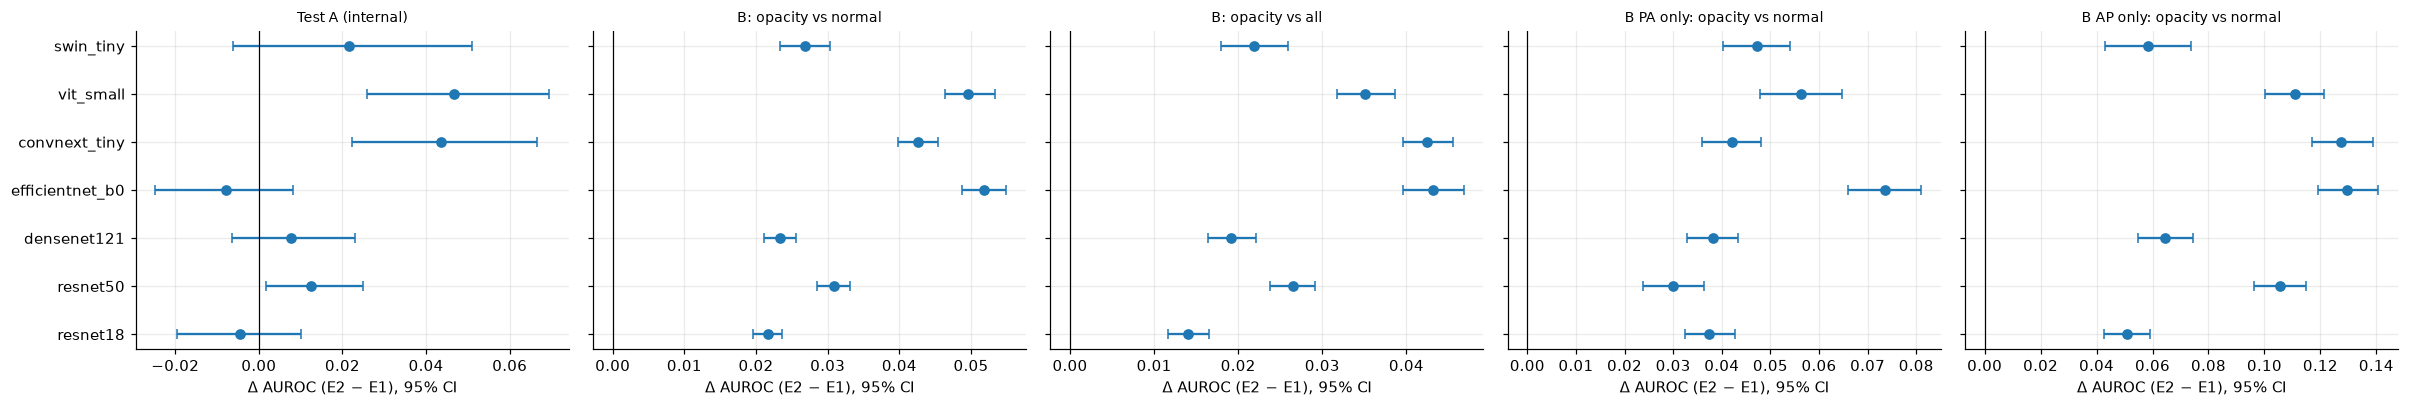

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(22, 3.8), sharey=True)
for ax, key in zip(axes, ALL_LABELS):
    d = e2_vs_e1[e2_vs_e1["eval"] == key].set_index("arch").reindex(arch_order)
    y = np.arange(len(d))
    ax.errorbar(d.delta_ensemble, y, xerr=[d.delta_ensemble - d.ci_lo, d.ci_hi - d.delta_ensemble], fmt="o", capsize=3)
    ax.axvline(0, color="k", lw=0.8); ax.set_title(ALL_LABELS[key], fontsize=9); ax.set_xlabel("Δ AUROC (E2 − E1), 95% CI")
axes[0].set_yticks(np.arange(len(arch_order)), arch_order)
plt.tight_layout(); plt.savefig(FIG / "e2_vs_e1_delta.png", bbox_inches="tight"); plt.show()

### Insights: conventional augmentation (E2)
* **E2 improves external performance for all 7 architectures, and every confidence interval excludes 0.** On B (opacity vs normal) the gain is +0.03 to +0.06 AUROC (EfficientNet-B0 +0.056, ConvNeXt +0.061). It also improves the secondary B task (+0.01 to +0.05).
* **The gain is real opacity detection, not better view detection.** Within-view gains are as large or larger: PA +0.04 to +0.08, AP +0.04 to +0.13. If augmentation only helped the model recognise AP films, within-view AUROC would not move.
* **Internal Test A is mixed:** −0.006 to +0.087. Significant gains appear only for ConvNeXt, ViT and ResNet-50, where augmentation mostly *stabilises* seeds that otherwise collapse on Test A. So augmentation's main benefit is out-of-distribution, which is the "Scenario A / beyond the source" pattern from the project plan.
* **In-domain validation would have rejected E2.** E2's best A-validation BCE is *higher* (worse) than E1's for 5 of 7 architectures (e.g. EfficientNet-B0 0.044 → 0.058, ConvNeXt 0.060 → 0.075). Augmentation makes the A shortcut harder to exploit, which costs in-domain fit and pays off externally. This is the clearest demonstration in the project that source-domain validation is a misleading guide to generalisation.
* E2 is therefore the stronger baseline that synthetic augmentation (E3/E4) must beat, not just E1.

Δ is computed on the seed-averaged scores of each configuration, with a paired, patient-clustered bootstrap (2,000 resamples). `delta_per_seed_mean` is the average of per-seed differences, a check that the effect is not an ensembling artefact.

**How to read it.** A CI entirely to the right of 0 means augmentation helped on that test set beyond resampling noise of the *test set*. The CI does not include training noise across seeds; compare `delta_per_seed_mean ± sd` for that. With 7 architectures × 5 test views there are 35 comparisons. Expect one or two "significant" results by chance at the 5% level. A consistent sign across architectures is stronger evidence than any single p-value.

## Does in-domain validation predict external performance?
Model selection, early stopping and HPO all use A-validation BCE. If lower validation loss reliably meant better B performance, in-domain selection would be safe. Each point below is one E1/E2 run. Spearman's ρ is computed over all runs and within each experiment.

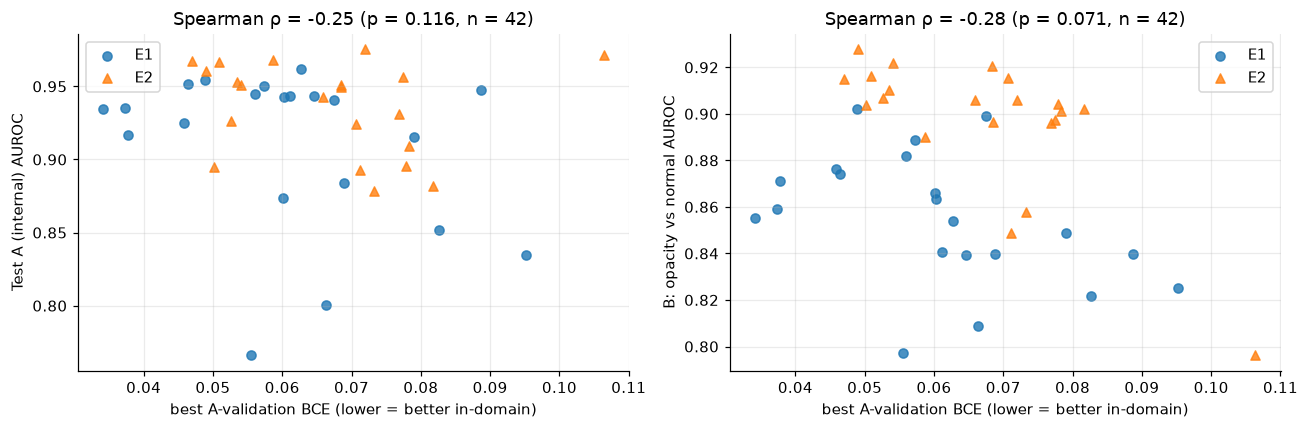

,runs,eval,"spearman_rho(val_bce, auroc)",p,n
0,E1,Test A (internal),-0.216,0.348,21
1,E1,B: opacity vs normal,-0.512,0.018,21
2,E1,B: opacity vs all,-0.495,0.023,21
3,E2,Test A (internal),-0.282,0.216,21
4,E2,B: opacity vs normal,-0.627,0.002,21
5,E2,B: opacity vs all,-0.449,0.041,21
6,both,Test A (internal),-0.246,0.116,42
7,both,B: opacity vs normal,-0.281,0.071,42
8,both,B: opacity vs all,-0.246,0.116,42


In [9]:
from scipy.stats import spearmanr
rr = runs[runs.experiment.isin(["E1", "E2"])].pivot_table(index=["experiment", "arch", "seed", "best_val_loss"], columns="eval", values="auroc").reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key in zip(axes, ["A_test:label", "B_external:label"]):
    for exp, mk in [("E1", "o"), ("E2", "^")]:
        d = rr[rr.experiment == exp]
        ax.scatter(d.best_val_loss, d[key], marker=mk, label=exp, alpha=0.8)
    rho, p = spearmanr(rr.best_val_loss, rr[key])
    ax.set_xlabel("best A-validation BCE (lower = better in-domain)"); ax.set_ylabel(f"{EVAL_LABELS[key]} AUROC")
    ax.set_title(f"Spearman ρ = {rho:.2f} (p = {p:.3f}, n = {len(rr)})"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "val_loss_vs_test.png", bbox_inches="tight"); plt.show()
rows = []
for exp in ["E1", "E2", "both"]:
    d = rr if exp == "both" else rr[rr.experiment == exp]
    for key in ["A_test:label", "B_external:label", "B_external:label_any"]:
        rho, p = spearmanr(d.best_val_loss, d[key]); rows.append({"runs": exp, "eval": EVAL_LABELS[key], "spearman_rho(val_bce, auroc)": rho, "p": p, "n": len(d)})
display(pd.DataFrame(rows).round(3))

A strongly negative ρ (lower val loss → higher AUROC) means validation is a useful guide. ρ near 0 for B means that, among already-good models, A-validation cannot tell which one will generalise. That is expected when validation shares the source's shortcut, and it is the core methodological limitation of single-source training.

**Insight.** *Within* an experiment, lower validation BCE does go with better B AUROC (E1: ρ = −0.51, p = 0.018; E2: ρ = −0.63, p = 0.002), so validation is useful for ranking architectures and seeds under a fixed training recipe. *Across* the two recipes the relationship breaks down (pooled ρ = −0.28, p = 0.07): E2 has worse validation loss but better B AUROC. Validation can choose *among* models trained the same way, but it cannot tell you which training recipe generalises. Test A correlates only weakly with validation (ρ ≈ −0.2 to −0.3, n.s.), which again shows that Test A is not distributed like validation.

## Seed ensembles: a free improvement?
Averaging the scores of the 3 seed models of one configuration (no extra training) usually improves ranking, because independent errors partly cancel. The table compares the mean single-model AUROC with the AUROC of the 3-seed average.

In [10]:
from cxr.analysis import seed_predictions
from sklearn.metrics import roc_auc_score
rows = []
for exp in ["E1", "E2"]:
    for arch in arch_order:
        for key in EVAL_LABELS:
            name, col = key.split(":")
            sp = seed_predictions(exp, arch, name)
            if sp.empty: continue
            sp = sp[sp[col].notna()]
            seeds = [c for c in sp if c.startswith("seed")]
            single = np.mean([roc_auc_score(sp[col], sp[c]) for c in seeds])
            rows.append({"experiment": exp, "arch": arch, "eval": EVAL_LABELS[key], "mean single AUROC": single,
                         "3-seed ensemble AUROC": roc_auc_score(sp[col], sp.prob_mean)})
ens = pd.DataFrame(rows)
ens["gain"] = ens["3-seed ensemble AUROC"] - ens["mean single AUROC"]
display(ens.pivot_table(index=["experiment", "arch"], columns="eval", values=["mean single AUROC", "3-seed ensemble AUROC", "gain"]).round(3))
ens.to_csv(RES / "seed_ensembles.csv", index=False)

3-seed ensemble AUROC                                                     gain                                        mean single AUROC  \
eval                           B: opacity vs all B: opacity vs normal Test A (internal) B: opacity vs all B: opacity vs normal Test A (internal) B: opacity vs all   
experiment arch                                                                                                                                                      
E1         convnext_tiny                   0.745                0.865             0.928             0.022                0.026             0.061             0.723   
           densenet121                     0.771                0.902             0.946             0.016                0.018             0.013             0.755   
           efficientnet_b0                 0.753                0.879             0.961             0.018                0.020             0.023             0.736   
           resnet18                        0.765                0.894             0.958             0.015                0.018             0.013             0.750   
           resnet50                        0.760                0.884             0.957             0.014                0.019             0.010             0.745   
           swin_tiny                       0.735                0.868             0.895             0.023                0.030             0.017             0.712   
           vit_small                       0.729                0.841             0.930             0.018                0.018             0.063             0.711   
E2         convnext_tiny                   0.787                0.908             0.972             0.010                0.008             0.018             0.777   
           densenet121                     0.790                0.925             0.953             0.012                0.010             0.007             0.778   
           efficientnet_b0                 0.797                0.931             0.953             0.019                0.016             0.021             0.778   
           resnet18                        0.779                0.916             0.953             0.011                0.010             0.014             0.768   
           resnet50                        0.786                0.915             0.969             0.008                0.008             0.002             0.778   
           swin_tiny                       0.757                0.895             0.917             0.021                0.025             0.033             0.736   
           vit_small                       0.764                0.891             0.976             0.019                0.024             0.051             0.745   

                                                                   
eval                       B: opacity vs normal Test A (internal)  
experiment arch                                                    
E1         convnext_tiny                  0.839             0.867  
           densenet121                    0.883             0.932  
           efficientnet_b0                0.859             0.937  
           resnet18                       0.876             0.945  
           resnet50                       0.865             0.947  
           swin_tiny                      0.838             0.878  
           vit_small                      0.823             0.866  
E2         convnext_tiny                  0.900             0.954  
           densenet121                    0.915             0.947  
           efficientnet_b0                0.915             0.932  
           resnet18                       0.906             0.939  
           resnet50                       0.907             0.967  
           swin_tiny                      0.870             0.884  
           vit_small                      0.867             0.926

**Insight.** Averaging three seeds adds +0.008 to +0.030 AUROC on B and up to +0.06 on Test A, with the largest gains for the unstable models (ConvNeXt, ViT, Swin), whose seeds make different errors. The best external results overall are E2 seed ensembles: EfficientNet-B0 0.931, DenseNet-121 0.925, ResNet-18 0.916, ResNet-50 0.915 (B, opacity vs normal). Ensembling is cheap at inference time for small models, and is a legitimate reported variant as long as members are not selected on B.

## Cost vs benefit

,train_time_s,best_step,steps_done,params_M,E1 B AUROC
arch,,,,,
resnet18,123.96,1216.67,1500.00,11.18,0.88
resnet50,148.81,750.00,1116.67,23.51,0.87
densenet121,107.38,833.33,1233.33,6.95,0.88
efficientnet_b0,79.38,316.67,716.67,4.01,0.86
convnext_tiny,200.64,416.67,816.67,27.82,0.84
vit_small,94.68,366.67,766.67,21.67,0.82
swin_tiny,149.38,350.00,750.00,27.52,0.84


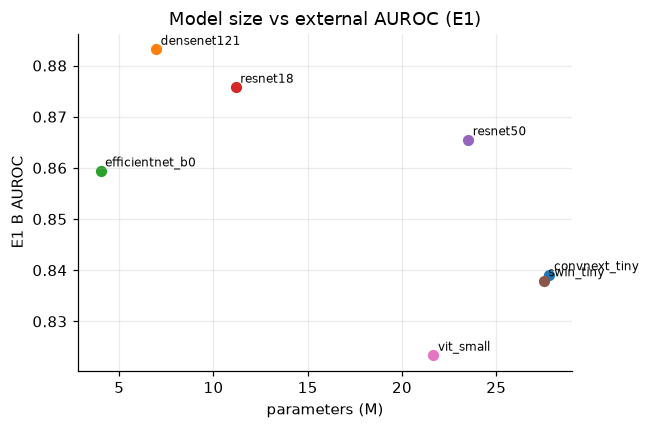

In [11]:
info = runs[runs.experiment == "E1"].drop_duplicates(["arch", "seed"]).groupby("arch").agg(
    train_time_s=("train_time_s", "mean"), best_step=("best_step", "mean"), steps_done=("steps_done", "mean"))
import torch, timm
from cxr.models import ARCHS as _A
info["params_M"] = [sum(p.numel() for p in timm.create_model(_A[a], pretrained=False, num_classes=1).parameters()) / 1e6 for a in info.index]
b_auc = runs[(runs.experiment == "E1") & (runs["eval"] == "B_external:label")].groupby("arch").auroc.mean()
info["E1 B AUROC"] = b_auc
display(info.reindex(arch_order).round(2))
fig, ax = plt.subplots(figsize=(6, 4))
for a, r in info.iterrows():
    ax.scatter(r.params_M, r["E1 B AUROC"], s=40); ax.annotate(a, (r.params_M, r["E1 B AUROC"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("parameters (M)"); ax.set_ylabel("E1 B AUROC"); ax.set_title("Model size vs external AUROC (E1)")
plt.tight_layout(); plt.savefig(FIG / "params_vs_b.png", bbox_inches="tight"); plt.show()

**Insight.** The smallest model, EfficientNet-B0 (4.0M parameters), trains fastest (≈80 s) and, with augmentation, gives the best external result. The 28M-parameter ConvNeXt-T and Swin-T are the slowest and among the weakest at this data size. ResNet-18 often ran into the 1,500-step cap (best step ≈1,200), so its budget was binding. A longer budget could help it slightly, but all comparisons here use the same cap by design.

**Selection consequence.** The pre-registered rule (best CNN + best transformer by A-validation BCE) selected **EfficientNet-B0** and **ViT-S** for the data experiments. In hindsight on B, DenseNet-121 and ResNet-18 had better E1 external AUROC than EfficientNet-B0, and Swin/ConvNeXt are comparable to ViT. This is the honest cost of not peeking at the external set, and it is the right way to do it.